In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

DATA_PATH = "train_u6lujuX_CVtuZ9i.csv"
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])

# Loan_ID is only a label for each row, so ii feel t can't help predict anything
df = df.drop(columns=["Loan_ID"])

Columns with missing values:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


In [4]:
# Dependents has a "3+" value, so i turn it into a plain 3 and make the column numeric
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)

y = (df["Loan_Status"] == "Y").astype(int)
df = df.drop(columns=["Loan_Status"])

# i think i have to Add up both incomes, since joint applicants are judged on what they earn together
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

for col in ["ApplicantIncome", "LoanAmount", "TotalIncome"]:
    df[col] = np.log1p(df[col])

df.describe().round(2)

,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,TotalIncome
count,599.00,614.00,614.00,592.00,600.00,564.00,614.00
mean,0.76,8.34,1621.25,4.87,342.00,0.84,8.67
std,1.02,0.65,2926.25,0.50,65.12,0.36,0.55
min,0.00,5.02,0.00,2.30,12.00,0.00,7.27
25%,0.00,7.97,0.00,4.62,360.00,1.00,8.33
50%,0.00,8.25,1188.50,4.86,360.00,1.00,8.60
75%,2.00,8.66,2297.25,5.13,360.00,1.00,8.93
max,3.00,11.30,41667.00,6.55,480.00,1.00,11.30


Share of applications by outcome:
Approved
Approved    0.687
Rejected    0.313
Name: proportion, dtype: float64


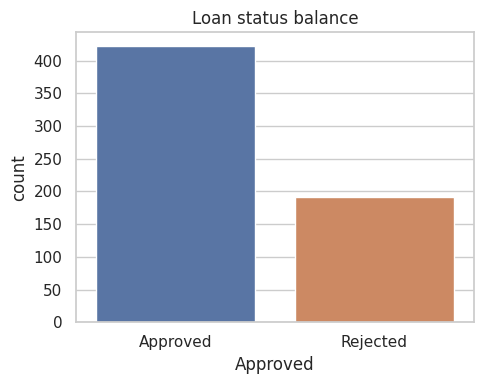

In [5]:
plot_df = df.copy()
plot_df["Approved"] = y.map({1: "Approved", 0: "Rejected"})

print("Share of applications by outcome:")
print(plot_df["Approved"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(data=plot_df, x="Approved", hue="Approved", order=["Approved", "Rejected"], legend=False)
plt.title("Loan status balance")
plt.tight_layout()
plt.savefig("fig1_class_balance.png", dpi=150)
plt.show()

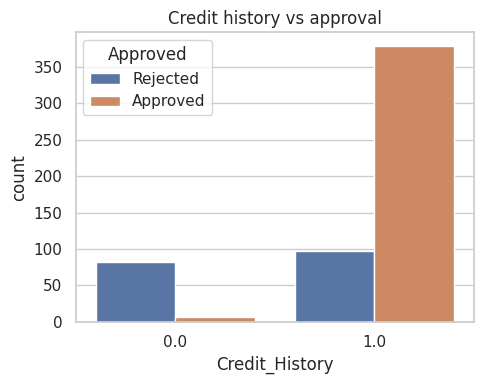

Approval rate by Credit_History:
Credit_History
0.0    0.079
1.0    0.796
Name: Loan_Status, dtype: float64


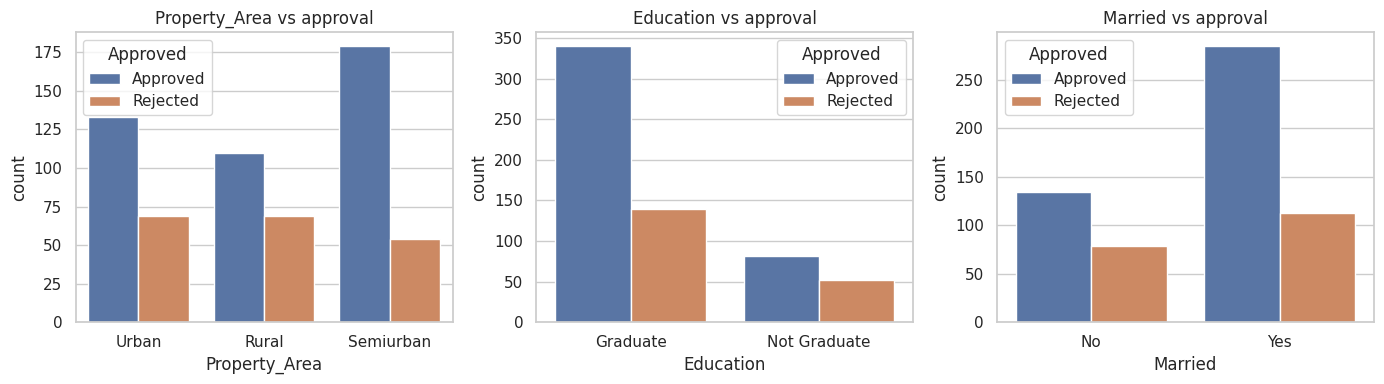

In [6]:

plt.figure(figsize=(5, 4))
sns.countplot(data=plot_df, x="Credit_History", hue="Approved")
plt.title("Credit history vs approval")
plt.tight_layout()
plt.savefig("fig2_credit_history.png", dpi=150)
plt.show()

print("Approval rate by Credit_History:")
print(y.groupby(df["Credit_History"]).mean().round(3))


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Property_Area", "Education", "Married"]):
    sns.countplot(data=plot_df, x=col, hue="Approved", ax=ax)
    ax.set_title(f"{col} vs approval")
plt.tight_layout()
plt.savefig("fig3_other_features.png", dpi=150)
plt.show()

In [7]:
# About 2 in 3 loans get approved, so stratify keeps that ratio in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

categorical_cols = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"]
numeric_cols = ["Dependents", "ApplicantIncome", "CoapplicantIncome", "LoanAmount",
                "Loan_Amount_Term", "Credit_History", "TotalIncome"]

# Filling gaps inside the pipeline means the fill values come from the training data only
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_steps, numeric_cols),
    ("cat", categorical_steps, categorical_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVC":                 SVC(random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
}

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

rows = []
fitted = {}

for name, model in models.items():
    pipe = make_pipeline(model)


    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)

    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)

    rows.append({
        "Model": name,
        "CV accuracy": cv_res["test_accuracy"].mean(),
        "CV F1 (macro)": cv_res["test_f1_macro"].mean(),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test precision": precision_score(y_test, pred),
        "Test recall (approved)": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
        # Of the applications that should be rejected, how many did the model catch?
        "Recall (rejected)": recall_score(y_test, pred, pos_label=0),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results.to_csv("model_comparison.csv")
results

,CV accuracy,CV F1 (macro),Test accuracy,Test precision,Test recall (approved),Test F1,Recall (rejected)
Model,,,,,,,
Logistic Regression,0.794,0.705,0.862,0.840,0.988,0.908,0.579
Decision Tree,0.762,0.670,0.854,0.845,0.965,0.901,0.605
Random Forest,0.772,0.698,0.829,0.856,0.906,0.880,0.658
SVC,0.794,0.702,0.854,0.832,0.988,0.903,0.553
KNN,0.784,0.701,0.846,0.837,0.965,0.896,0.579


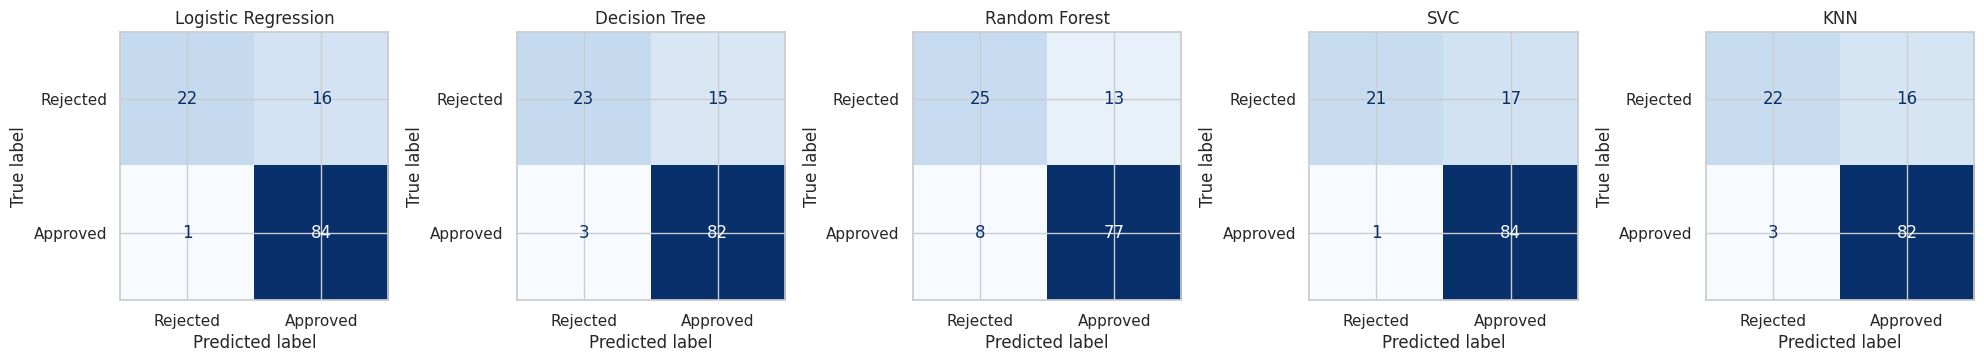


Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Decision Tree
              precision    recall  f1-score   support

    Rejected       0.88      0.61      0.72        38
    Approved       0.85      0.96      0.90        85

    accuracy                           0.85       123
   macro avg       0.86      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123


Random Forest
              precision    recall  f1-score   support

    Rejected       0.76      0.66      0.70        38
    Approved       0.86      0.91      0.88        85

    accuracy                           0.83       123
   macro avg       0.81      0.78      0.79       123
weighted avg       0.83

In [9]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pipe.predict(X_test), display_labels=["Rejected", "Approved"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("fig4_confusion_matrices.png", dpi=150)
plt.show()

for name, pipe in fitted.items():
    print(f"\n{name}")
    print(classification_report(y_test, pipe.predict(X_test),
                                target_names=["Rejected", "Approved"], zero_division=0))

In [10]:

best_name = results["CV F1 (macro)"].idxmax()
print("Best model by CV macro F1:", best_name)

param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10],
                            "model__class_weight": [None, "balanced"]},
    "Decision Tree":       {"model__max_depth": [3, 5, 7, None],
                            "model__min_samples_leaf": [1, 5, 10]},
    "Random Forest":       {"model__n_estimators": [100, 200, 400],
                            "model__max_depth": [3, 5, None],
                            "model__min_samples_leaf": [1, 5]},
    "SVC":                 {"model__C": [0.1, 1, 10],
                            "model__kernel": ["linear", "rbf"]},
    "KNN":                 {"model__n_neighbors": [3, 5, 7, 11, 15],
                            "model__weights": ["uniform", "distance"]},
}

grid = GridSearchCV(make_pipeline(models[best_name]), param_grids[best_name],
                    cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", round(grid.best_score_, 3))

Best model by CV macro F1: Logistic Regression
Best parameters: {'model__C': 0.1, 'model__class_weight': None}
Best CV macro F1: 0.709


              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123

Confusion matrix (rows = actual, columns = predicted):
[[22 16]
 [ 1 84]]


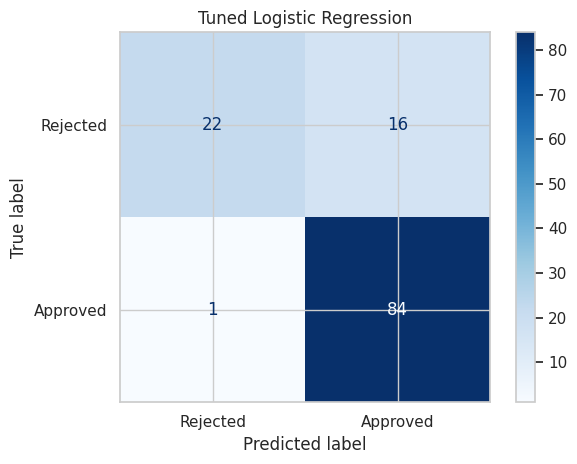

In [11]:
tuned_pred = grid.best_estimator_.predict(X_test)

print(classification_report(y_test, tuned_pred,
                            target_names=["Rejected", "Approved"], zero_division=0))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, tuned_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=["Rejected", "Approved"], cmap="Blues")
plt.title(f"Tuned {best_name}")
plt.tight_layout()
plt.savefig("fig5_tuned_confusion_matrix.png", dpi=150)
plt.show()